# Task 1 — Direct Preference Optimization (DPO)

**What this notebook does.** It (1) validates and fixes the deliberate defect in the starter DPO objective,
(2) trains the standard one-epoch DPO adapter from Qwen2.5-1.5B-Instruct with LoRA, (3) runs the
β ∈ {0.03, 0.10, 0.30} short-run regularisation study, (4) trains the length-balanced DPO model and
evaluates length confounding per stratum, and (5) surfaces qualitative examples.

All heavy work is done by the Python modules in `task1_dpo/` (each in a fresh process to keep RAM/VRAM
safe). Every cell below that launches training **skips automatically if the output already exists**, so
re-running the notebook only re-does the analysis. Raw logs: `results/logs/t1.log`; machine-readable
results: `results/task1_dpo/`.

| Item | Setting (from `configs/dpo.yaml`) |
|---|---|
| Policy / reference | Qwen2.5-1.5B-Instruct + LoRA (r=8, α=16, dropout 0.05, q_proj/v_proj); reference = same weights with LoRA disabled |
| Optimiser | AdamW, lr 2e-5, constant, weight decay 0, grad-clip 1.0 |
| Batch | 2 pairs × 8 accumulation = 16 pairs / step |
| Max sequence length | 768 tokens. **Overlength filter** (TA-approved option): a pair is kept only if prompt + max(chosen, rejected) + EOS ≤ 768, so nothing is ever truncated; applied identically to every DPO training and evaluation file |
| Standard run | β = 0.10, 1 epoch over the standard training file |
| β study | β ∈ {0.03, 0.10, 0.30}, first 600 (fitting) training pairs, otherwise identical |
| Generation protocol | 1 sample / held-out prompt (prompts ≤ 512 tokens), T = 0.7, top-p 0.9, ≤ 256 new tokens, seed 6304 |
| Reward model | `yavuz-ai/qwen2.5-1.5b-rm-ultrafeedback` (8-bit, frozen) |

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common.analysis import setup_style, savefig, jl, js, excerpt, show_log_tail, grep_log, PALETTE
from common.data import load_yaml, read_jsonl, repo_path
from common.orchestration import run_module, set_log_file
setup_style()
print("repo root:", ROOT)
cfg = load_yaml("configs/dpo.yaml")
R = Path(cfg["results_dir"])
set_log_file("results/logs/t1_notebook.log")

repo root: /workspace/pa2


## 1. Validating the DPO objective (deliberate starter defect)

The manual defines

$$\mathcal L_{\text{DPO}} = -\mathbb E\Big[\log\sigma\big(\beta\,[\underbrace{(\log\pi_\theta(y^+|x)-\log\pi_\theta(y^-|x))}_{\text{policy margin}} - \underbrace{(\log\pi_{\text{ref}}(y^+|x)-\log\pi_{\text{ref}}(y^-|x))}_{\text{reference margin}}]\big)\Big].$$

The starter computed `beta * (policy_margin + ref_margin)`. With the sign error the loss is **not** `log 2`
at initialisation (when π_θ = π_ref) and the policy is rewarded for agreeing with whatever the reference
already prefers, instead of for *changing* its relative preference. The fix is `policy_margin - ref_margin`.

In [2]:
import inspect, task1_dpo.dpo as dpo_mod
src = inspect.getsource(dpo_mod.dpo_loss)
print(src[src.index("# FIX"):src.index("loss = -F.logsigmoid")])
from scripts.smoke_tests import test_dpo, RESULTS
test_dpo()
assert all(ok for _, ok, _ in RESULTS), "objective validation failed"

# FIX (deliberate starter defect): the DPO logit is beta times the difference of the
    # policy/reference log-ratios,
    #   [log pi(y+|x) - log ref(y+|x)] - [log pi(y-|x) - log ref(y-|x)]
    #   = (policy_chosen - policy_rejected) - (ref_chosen - ref_rejected),
    # i.e. policy_margin MINUS ref_margin. The starter added ref_margin, which rewards the
    # policy for agreeing with whatever the reference already prefers instead of measuring
    # the change relative to the reference.
    logits = beta * (
        policy_margin - ref_margin
    )

    
[PASS] DPO loss matches manual equation 0.620957 vs 0.620957
[PASS] DPO logit = beta*(policy_margin - ref_margin) 
[PASS] DPO at initialisation: loss = log 2 0.693147
[PASS] Starter bug detectable at init (buggy loss != log 2) buggy=0.6444
[PASS] DPO gradient pushes chosen log-prob up 


### 1b. Numerical demonstration on real held-out pairs (reference log-probs)
At initialisation π_θ = π_ref, so the correct loss is exactly log 2 ≈ 0.693 for *every* pair; the buggy
version instead depends on the reference model's own preference.

In [3]:
p = R / "eval_sft_pairs.jsonl"
if p.exists():
    import torch, torch.nn.functional as F
    d = jl(p)
    rc, rr = torch.tensor(d.ref_chosen.values), torch.tensor(d.ref_rejected.values)
    beta = 0.1
    correct = -F.logsigmoid(beta * ((rc - rr) - (rc - rr))).mean().item()
    buggy = -F.logsigmoid(beta * ((rc - rr) + (rc - rr))).mean().item()
    print(f"held-out pairs: {len(d)} | correct loss at init = {correct:.4f} (log2 = {np.log(2):.4f}) | buggy loss at init = {buggy:.4f}")
    print(f"reference model already prefers the chosen response on {(rc > rr).float().mean():.3f} of held-out pairs (sequence log-prob)")
else:
    print("run the SFT evaluation first")

held-out pairs: 240 | correct loss at init = 0.6931 (log2 = 0.6931) | buggy loss at init = 14.7119
reference model already prefers the chosen response on 0.504 of held-out pairs (sequence log-prob)


## 2. The preference data and its length structure (a property of the **dataset**)

In [4]:
from task1_dpo.analyze_length import dataset_length_stats
from common.models import load_tokenizer
p = R / "length_dataset_stats.json"
if p.exists():
    ds = pd.DataFrame(js(p))
else:
    tok = load_tokenizer(cfg["base_model"])
    ds = pd.DataFrame([dataset_length_stats(read_jsonl(cfg["paths"][k]), tok, k) for k in ["dpo_standard_train", "dpo_length_train", "dpo_standard_eval", "dpo_length_eval"]])
display(ds.drop(columns=["strata_counts", "dropped_by_stratum"], errors="ignore").set_index("dataset").T)
for name in ["dpo_standard_train", "dpo_standard_eval"]:
    ids = js(R / "train_ids_standard.json") if name == "dpo_standard_train" and (R / "train_ids_standard.json").exists() else None
    if ids:
        print(f"standard training pairs used: {ids['n_used']} (dropped {ids['n_dropped_overlength']} whose prompt + longer response > {cfg['max_sequence_length']} tokens)")

dataset,standard_train (all),standard_train (after filter),length_balanced_train (all),length_balanced_train (after filter),standard_eval (all),standard_eval (after filter),length_stratified_eval (all),length_stratified_eval (after filter)
n_pairs,1500.0000,1214.0000,1500.0000,1400.0000,300.0000,240.0000,246.0000,230.0000
chosen_tokens_mean,282.1147,227.0231,156.8553,155.4714,274.4033,206.1458,147.4553,146.7609
rejected_tokens_mean,239.6647,188.0980,151.6920,150.2879,243.7567,186.5875,144.7602,143.7739
frac_chosen_longer,0.5627,0.5659,0.4913,0.4907,0.5333,0.5292,0.4837,0.4783
frac_rejected_longer,0.4220,0.4168,0.4860,0.4871,0.4433,0.4458,0.5000,0.5043
mean_len_diff_chosen_minus_rejected,42.4500,38.9250,5.1633,5.1836,30.6467,19.5583,2.6951,2.9870
median_len_diff,18.0000,16.0000,0.0000,0.0000,5.0000,3.5000,-0.5000,-1.0000
frac_relative_diff_gt_20pct_chosen_longer,0.4427,0.4522,0.3180,0.3143,0.3967,0.4000,0.3130,0.3043
frac_relative_diff_gt_20pct_rejected_longer,0.3013,0.3007,0.3200,0.3193,0.3333,0.3458,0.3211,0.3174
spearman_len_diff_vs_score_diff,0.0782,0.0860,0.0535,0.0660,0.1425,0.0960,0.0459,0.0736


standard training pairs used: 1214 (dropped 286 whose prompt + longer response > 768 tokens)


saved figure: report/figures/t1_dataset_length_difference.pdf


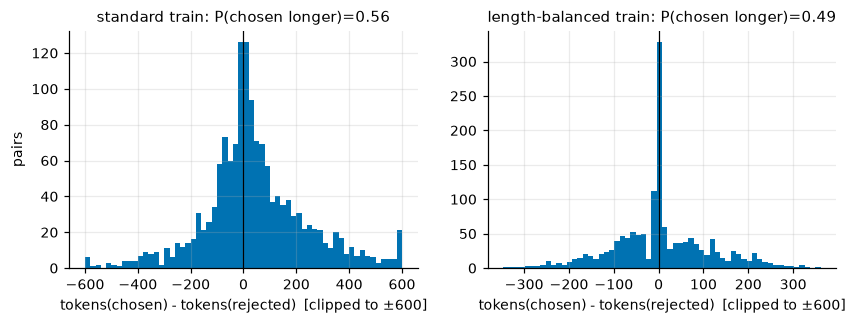

In [5]:
from common.models import load_tokenizer
from common.data import preference_responses
tok = load_tokenizer(cfg["base_model"])
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=False)
for ax, key, title in [(axes[0], "dpo_standard_train", "standard train"), (axes[1], "dpo_length_train", "length-balanced train")]:
    rows = read_jsonl(cfg["paths"][key])
    diff = []
    for r in rows:
        c, j = preference_responses(r)
        diff.append(len(tok(c, add_special_tokens=False)["input_ids"]) - len(tok(j, add_special_tokens=False)["input_ids"]))
    diff = np.clip(diff, -600, 600)
    ax.hist(diff, bins=60, color=PALETTE[0])
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{title}: P(chosen longer)={np.mean(np.array(diff) > 0):.2f}")
    ax.set_xlabel("tokens(chosen) - tokens(rejected)  [clipped to ±600]")
axes[0].set_ylabel("pairs")
savefig(fig, "t1_dataset_length_difference"); plt.show()

## 3. Standard DPO (β = 0.10, one epoch)
Training and evaluation are launched below (skipped if already done). The loop:
for each micro-batch, chosen and rejected sequences share one forward pass; the frozen reference
log-probs are computed with the LoRA adapter disabled (`reference_mode`); the corrected `dpo_loss` is
divided by the accumulation window and back-propagated; every 8 micro-batches the LoRA gradients are
clipped to norm 1 and AdamW steps.

In [6]:
run_module("task1_dpo.train", "--config", "configs/dpo.yaml", "--run-name", "standard",
           skip_if_exists="outputs/task1_dpo/standard/adapter_model.safetensors")
run_module("task1_dpo.evaluate", "--config", "configs/dpo.yaml", "--adapter", "none", "--name", "sft",
           skip_if_exists="results/task1_dpo/eval_sft.json")
run_module("task1_dpo.evaluate", "--config", "configs/dpo.yaml", "--adapter", "outputs/task1_dpo/standard", "--name", "standard",
           skip_if_exists="results/task1_dpo/eval_standard.json")
print("\n--- training log (results/logs/t1.log) ---")
grep_log("results/logs/t1.log", "[standard] step")
display(pd.Series(js(R / "train_summary_standard.json")).to_frame("standard run"))

[skip] task1_dpo.train --config configs/dpo.yaml --run-name standard  (found outputs/task1_dpo/standard/adapter_model.safetensors)


[skip] task1_dpo.evaluate --config configs/dpo.yaml --adapter none --name sft  (found results/task1_dpo/eval_sft.json)


[skip] task1_dpo.evaluate --config configs/dpo.yaml --adapter outputs/task1_dpo/standard --name standard  (found results/task1_dpo/eval_standard.json)



--- training log (results/logs/t1.log) ---
[standard] step 5/76 loss=0.6955 acc=0.312 margin=-0.005 gnorm=1.784 t=28s
[standard] step 10/76 loss=0.6922 acc=0.500 margin=0.002 gnorm=1.566 t=47s
[standard] step 15/76 loss=0.6923 acc=0.438 margin=0.002 gnorm=1.861 t=66s
[standard] step 5/76 loss=0.6948 acc=0.250 margin=-0.003 gnorm=1.784 t=25s
[standard] step 10/76 loss=0.6949 acc=0.562 margin=-0.004 gnorm=1.572 t=52s
[standard] step 15/76 loss=0.6916 acc=0.562 margin=0.003 gnorm=1.858 t=80s
[standard] step 20/76 loss=0.6910 acc=0.625 margin=0.004 gnorm=1.828 t=107s
[standard] step 25/76 loss=0.6915 acc=0.625 margin=0.003 gnorm=1.789 t=134s
[standard] step 30/76 loss=0.6930 acc=0.438 margin=0.000 gnorm=1.744 t=158s
[standard] step 35/76 loss=0.6987 acc=0.562 margin=-0.011 gnorm=2.101 t=185s
[standard] step 40/76 loss=0.6859 acc=0.688 margin=0.015 gnorm=2.050 t=214s
[standard] step 45/76 loss=0.6883 acc=0.500 margin=0.010 gnorm=1.797 t=242s
[standard] step 50/76 loss=0.6795 acc=0.562 marg

,standard run
run,standard
beta,0.1
dataset,data/dpo_standard_train.jsonl
n_pairs,1214
epochs,1
optimizer_steps,76
effective_batch_pairs,16
learning_rate,0.0
max_sequence_length,768
lora,"{'r': 8, 'alpha': 16, 'dropout': 0.05, 'target..."


saved figure: report/figures/t1_standard_training.pdf


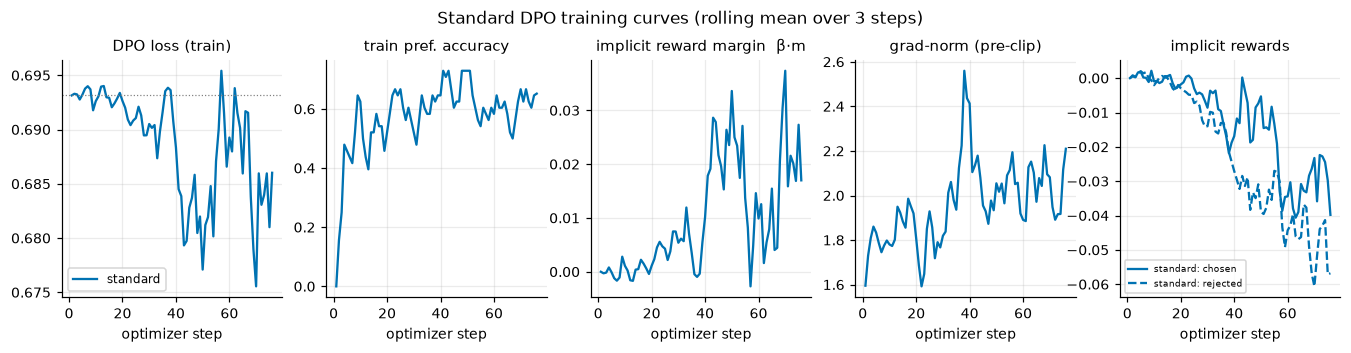

In [7]:
def plot_train(names, title, fname, smooth=3):
    fig, axes = plt.subplots(1, 5, figsize=(15, 2.8))
    for i, n in enumerate(names):
        p = R / f"train_log_{n}.jsonl"
        if not p.exists():
            continue
        d = jl(p)
        x = d.step
        for ax, col, lab in zip(axes, ["loss", "acc", "margin", "grad_norm", None], ["DPO loss (train)", "train pref. accuracy", "implicit reward margin  β·m", "grad-norm (pre-clip)", "implicit rewards"]):
            if col is None:
                ax.plot(x, d.chosen_reward.rolling(smooth, min_periods=1).mean(), color=PALETTE[i], label=f"{n}: chosen")
                ax.plot(x, d.rejected_reward.rolling(smooth, min_periods=1).mean(), color=PALETTE[i], ls="--", label=f"{n}: rejected")
            else:
                ax.plot(x, d[col].rolling(smooth, min_periods=1).mean(), color=PALETTE[i], label=n)
            ax.set_title(lab); ax.set_xlabel("optimizer step")
    axes[0].axhline(np.log(2), color="grey", lw=0.8, ls=":")
    axes[0].legend(); axes[4].legend(fontsize=6)
    fig.suptitle(title, y=1.04)
    savefig(fig, fname); plt.show()

plot_train(["standard"], "Standard DPO training curves (rolling mean over 3 steps)", "t1_standard_training")

In [8]:
def eval_row(name):
    s = js(R / f"eval_{name}.json")
    h, g, w = s["heldout"], s.get("generation", {}), s.get("word_limit", {})
    return {"condition": name, "beta": s["beta"],
            "heldout DPO loss (own β)": h["dpo_loss_own_beta"], "heldout DPO loss (β=0.1)": h["dpo_loss_beta_0.10"],
            "pref. accuracy": h["preference_accuracy"], "ties": h["tie_fraction"], "mean margin m_θ": h["margin_mean"],
            "KL token-mean": g.get("kl_token_mean"), "KL per-seq": g.get("kl_seq_mean"),
            "RM score": g.get("reward_mean"), "RM std": g.get("reward_std"),
            "len mean": g.get("length", {}).get("mean"), "len std": g.get("length", {}).get("std"), "len IQR": g.get("length", {}).get("iqr"),
            "trunc. rate": g.get("truncation_rate"), "entropy": g.get("entropy_token_mean"),
            "word-limit compliance": w.get("compliance_rate")}
std_tab = pd.DataFrame([eval_row(n) for n in ["sft", "standard"] if (R / f"eval_{n}.json").exists()]).set_index("condition")
display(std_tab.T)

condition,sft,standard
beta,0.1000,0.1000
heldout DPO loss (own β),0.6931,0.6797
heldout DPO loss (β=0.1),0.6931,0.6797
pref. accuracy,0.0000,0.6292
ties,1.0000,0.0167
mean margin m_θ,0.0000,0.2943
KL token-mean,0.0000,0.0001
KL per-seq,0.0000,0.0149
RM score,1.4613,1.4865
RM std,1.2438,1.1981


*Notes on the conventions.* Preference accuracy counts pairs with m_θ > 0 (the SFT reference has m_θ = 0
for every pair by construction, i.e. 100 % ties). The KL column is the course's sampled-response estimator
`sampled_kl` = mean over all generated response tokens of log π_θ − log π_ref (token-pooled), and the
per-sequence column sums it over each response; both are reported for every condition. Responses are
sampled at T = 0.7 while log-probs are evaluated at T = 1, so this estimator can be slightly negative for
policies very close to the reference.

## 4. Regularisation-strength study: β ∈ {0.03, 0.10, 0.30}
Short runs from the **original** initialisation on the first 600 fitting training pairs (≈38 optimizer
steps), same seed/optimizer/LoRA. The standard run uses a different budget (1 epoch ≈ 91 steps) and is
shown only as a reference row.

In [9]:
run_module("task1_dpo.ablate_beta", "--config", "configs/dpo.yaml")
beta_tab = pd.read_csv(R / "dpo_summary_table.csv").set_index("condition")
display(beta_tab.T)

[run] python -m task1_dpo.ablate_beta --config configs/dpo.yaml


Required beta values: [0.03, 0.1, 0.3]


Short-run examples per condition: 600


[skip] task1_dpo.train --config configs/dpo.yaml --run-name beta_0.03 --output outputs/task1_dpo/beta_0.03 --beta 0.03 --max-examples 600  (found outputs/task1_dpo/beta_0.03/adapter_model.safetensors)


[skip] task1_dpo.evaluate --config configs/dpo.yaml --adapter outputs/task1_dpo/beta_0.03 --name beta_0.03 --beta 0.03  (found results/task1_dpo/eval_beta_0.03.json)


...

 standard         1 epoch, all pairs  0.10                   0.679714                   0.679714          0.629167             0.294346       0.000104     0.014942       1.486488      1.198120 143.536797 105.123022    222.5         0.389610 0.956952                   0.58


beta_0.03 short run, first 600 pairs  0.03                   0.691208                   0.686872          0.629167             0.130898      -0.000203    -0.029160       1.448475      1.218398 143.385281 105.324317    222.5         0.359307 0.946812                   0.56


beta_0.10 short run, first 600 pairs  0.10                   0.687158                   0.687158          0.608333             0.124856      -0.000185    -0.026574       1.487598      1.208310 143.303030 105.830972    223.5         0.376623 0.939788                   0.56


beta_0.30 short run, first 600 pairs  0.30                   0.678352                   0.687754          0.608333             0.112485      -0.000183    -0.026135       1.455763      1.238249 142.792208 105.762285    223.5         0.367965 0.935868                   0.54


condition,sft,standard,beta_0.03,beta_0.10,beta_0.30
budget,none (reference policy),"1 epoch, all pairs","short run, first 600 pairs","short run, first 600 pairs","short run, first 600 pairs"
beta,0.1,0.1,0.03,0.1,0.3
heldout_dpo_loss_own_beta,0.6931,0.6797,0.6912,0.6872,0.6784
heldout_dpo_loss_beta0.10,0.6931,0.6797,0.6869,0.6872,0.6878
heldout_pref_acc,0.0,0.6292,0.6292,0.6083,0.6083
heldout_margin_mean,0.0,0.2943,0.1309,0.1249,0.1125
kl_token_mean,0.0,0.0001,-0.0002,-0.0002,-0.0002
kl_seq_mean,0.0,0.0149,-0.0292,-0.0266,-0.0261
rm_score_mean,1.4613,1.4865,1.4485,1.4876,1.4558
rm_score_std,1.2438,1.1981,1.2184,1.2083,1.2382


saved figure: report/figures/t1_beta_training.pdf


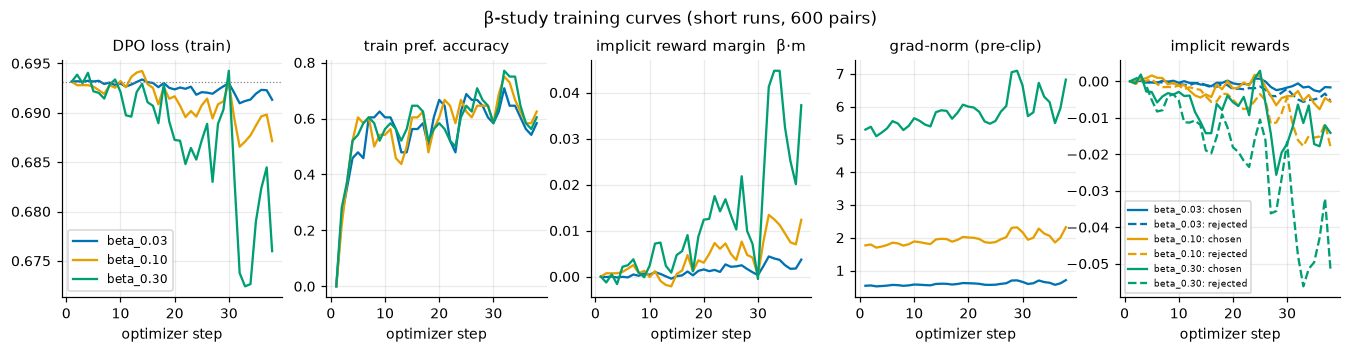

saved figure: report/figures/t1_beta_study.pdf


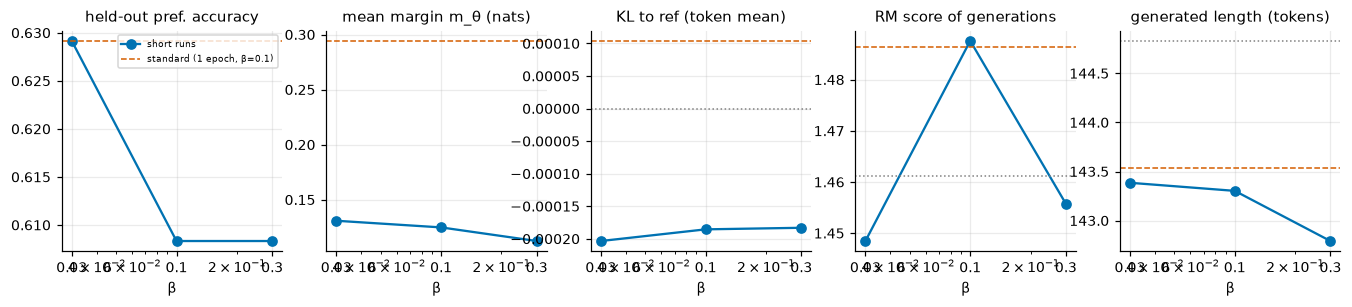

In [10]:
plot_train(["beta_0.03", "beta_0.10", "beta_0.30"], "β-study training curves (short runs, 600 pairs)", "t1_beta_training")
b = beta_tab.loc[[c for c in beta_tab.index if c.startswith("beta_")]].sort_values("beta")
fig, axes = plt.subplots(1, 5, figsize=(15, 2.6))
cols = [("heldout_pref_acc", "held-out pref. accuracy"), ("heldout_margin_mean", "mean margin m_θ (nats)"),
        ("kl_token_mean", "KL to ref (token mean)"), ("rm_score_mean", "RM score of generations"), ("len_mean", "generated length (tokens)")]
for ax, (c, lab) in zip(axes, cols):
    ax.plot(b.beta, b[c], "o-", color=PALETTE[0], label="short runs")
    if "standard" in beta_tab.index:
        ax.axhline(beta_tab.loc["standard", c], color=PALETTE[3], ls="--", lw=1, label="standard (1 epoch, β=0.1)")
    if "sft" in beta_tab.index and c not in ("heldout_pref_acc", "heldout_margin_mean"):
        ax.axhline(beta_tab.loc["sft", c], color="grey", ls=":", lw=1, label="SFT reference")
    ax.set_xscale("log"); ax.set_xticks(b.beta); ax.set_xticklabels(b.beta); ax.set_xlabel("β"); ax.set_title(lab)
axes[0].legend(fontsize=6)
savefig(fig, "t1_beta_study"); plt.show()

Monotonicity check over the tested range (sign of successive differences as β increases):

In [11]:
for c in ["heldout_pref_acc", "heldout_margin_mean", "kl_token_mean", "kl_seq_mean", "rm_score_mean", "len_mean"]:
    v = b[c].values
    diffs = np.sign(np.diff(v))
    print(f"{c:22s} values={np.round(v, 4)}  monotonic={'yes' if (diffs >= 0).all() or (diffs <= 0).all() else 'no'}")

heldout_pref_acc       values=[0.6292 0.6083 0.6083]  monotonic=yes
heldout_margin_mean    values=[0.1309 0.1249 0.1125]  monotonic=yes
kl_token_mean          values=[-0.0002 -0.0002 -0.0002]  monotonic=yes
kl_seq_mean            values=[-0.0292 -0.0266 -0.0261]  monotonic=yes
rm_score_mean          values=[1.4485 1.4876 1.4558]  monotonic=no
len_mean               values=[143.3853 143.303  142.7922]  monotonic=yes


## 5. Length-confounding study
The length-balanced file has 500 pairs in each stratum (preferred-longer / length-matched /
rejected-longer). We train a second DPO model on it (one epoch, same settings as standard) and evaluate
**both** models on the supplied length-stratified held-out set (82 pairs per stratum), on generated
length, and on explicit word-limit compliance (10 fixed prompts × 5 samples).

In [12]:
run_module("task1_dpo.analyze_length", "--config", "configs/dpo.yaml")
lt = pd.read_csv(R / "length_confounding_table.csv").set_index("condition")
display(lt.T)

[run] python -m task1_dpo.analyze_length --config configs/dpo.yaml


Length-balanced train rows: 1500


Length-stratified eval rows: 246


[skip] task1_dpo.train --config configs/dpo.yaml --run-name length_balanced --dataset data/dpo_length_balanced_train.jsonl --output outputs/task1_dpo/length_balanced  (found outputs/task1_dpo/length_balanced/adapter_model.safetensors)


[skip] task1_dpo.evaluate --config configs/dpo.yaml --adapter outputs/task1_dpo/length_balanced --name length_balanced  (found results/task1_dpo/eval_length_balanced.json)


...

wl07                 49.4  53.6     54.0             0.2  0.2      0.2


wl08                 33.2  32.0     31.4             0.8  1.0      1.0


wl09                 25.2  26.4     25.2             1.0  1.0      1.0


wl10                 69.2  74.2     64.2             0.0  0.0      0.0


condition,sft,standard,length_balanced,beta_0.03,beta_0.10,beta_0.30
acc_preferred_longer,0.0000,0.4459,0.3919,0.4865,0.4730,0.4865
margin_preferred_longer,0.0000,-0.0612,-0.5030,-0.0348,-0.0204,-0.0288
acc_length_matched,0.0000,0.5625,0.6125,0.5875,0.5875,0.5500
margin_length_matched,0.0000,0.1257,0.3142,0.0589,0.0470,0.0578
acc_rejected_longer,0.0000,0.6842,0.7500,0.6974,0.6974,0.7105
margin_rejected_longer,0.0000,0.4548,1.3280,0.1997,0.1843,0.1688
acc_all_strata,0.0000,0.5652,0.5870,0.5913,0.5870,0.5826
acc_standard_heldout,0.0000,0.6292,0.6042,0.6292,0.6083,0.6083
gen_len_mean,144.8312,143.5368,143.8095,143.3853,143.3030,142.7922
gen_len_std,106.2486,105.1230,105.7681,105.3243,105.8310,105.7623


saved figure: report/figures/t1_length_confounding.pdf


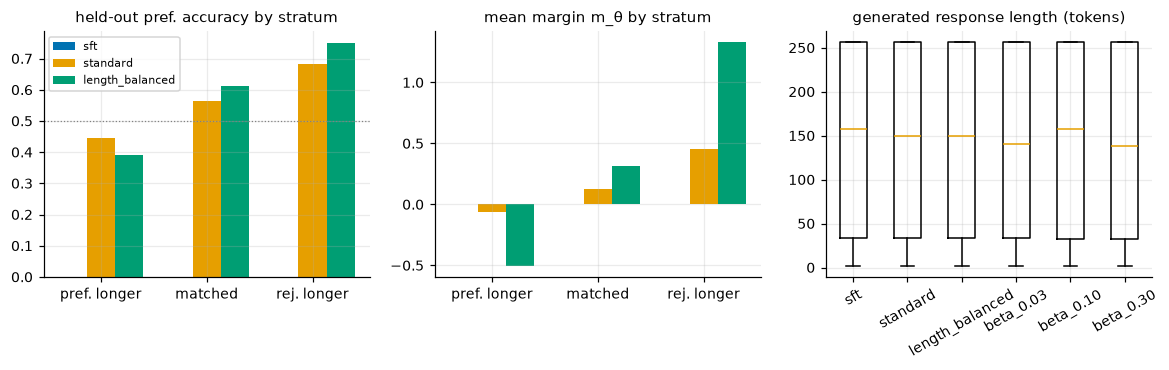

In [13]:
conds = [c for c in ["sft", "standard", "length_balanced"] if c in lt.index]
strata = ["preferred_longer", "length_matched", "rejected_longer"]
fig, axes = plt.subplots(1, 3, figsize=(13, 2.9))
x = np.arange(len(strata)); w = 0.8 / max(len(conds), 1)
for i, c in enumerate(conds):
    axes[0].bar(x + i * w, [lt.loc[c, f"acc_{s}"] for s in strata], w, label=c, color=PALETTE[i])
    axes[1].bar(x + i * w, [lt.loc[c, f"margin_{s}"] for s in strata], w, label=c, color=PALETTE[i])
for ax, t in zip(axes[:2], ["held-out pref. accuracy by stratum", "mean margin m_θ by stratum"]):
    ax.set_xticks(x + w * (len(conds) - 1) / 2); ax.set_xticklabels(["pref. longer", "matched", "rej. longer"]); ax.set_title(t)
axes[0].axhline(0.5, color="grey", ls=":", lw=0.8); axes[0].legend(fontsize=7)
gl = {c: jl(R / f"eval_{c}_generations.jsonl").response_tokens for c in conds + [c for c in ["beta_0.03", "beta_0.10", "beta_0.30"] if (R / f"eval_{c}_generations.jsonl").exists()]}
axes[2].boxplot(list(gl.values()), tick_labels=list(gl.keys()), showfliers=False)
axes[2].set_title("generated response length (tokens)"); axes[2].tick_params(axis="x", rotation=30)
savefig(fig, "t1_length_confounding"); plt.show()

,compliance,words_mean,words_std,reward_mean,mean words over limit (violations)
condition,,,,,
length_balanced,0.62,37.80,17.0258,3.4634,15.3684
sft,0.56,40.18,20.6493,3.4354,17.9545
standard,0.58,38.34,17.5866,3.4014,15.5714


words                     compliance              
condition       length_balanced   sft standard length_balanced  sft standard
prompt_id limit                                                             
wl01      40.0             31.4  33.2     31.4             1.0  1.0      1.0
wl02      25.0             26.8  27.6     27.6             0.4  0.2      0.2
wl03      30.0             24.4  24.2     23.2             1.0  1.0      1.0
wl04      35.0             38.6  42.0     42.0             0.4  0.2      0.2
wl05      45.0             52.8  61.6     56.8             0.6  0.4      0.6
wl06      30.0             27.0  27.0     27.6             0.8  0.6      0.6
wl07      35.0             49.4  53.6     54.0             0.2  0.2      0.2
wl08      40.0             33.2  32.0     31.4             0.8  1.0      1.0
wl09      30.0             25.2  26.4     25.2             1.0  1.0      1.0
wl10      45.0             69.2  74.2     64.2             0.0  0.0      0.0

saved figure: report/figures/t1_word_limit.pdf


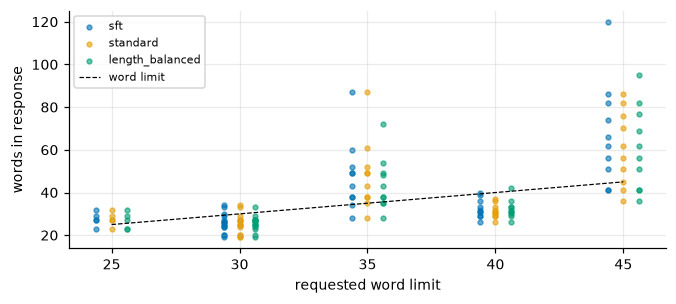

In [14]:
wl = pd.concat([jl(R / f"eval_{c}_wordlimit.jsonl").assign(condition=c) for c in conds], ignore_index=True)
wl["limit"] = wl.prompt.str.extract(r"(\d+)\s+words").astype(float)
summary_wl = wl.groupby("condition").agg(compliance=("compliant", "mean"), words_mean=("words", "mean"), words_std=("words", "std"),
                                          over_limit_words=("words", lambda s: np.nan), reward_mean=("reward", "mean"))
summary_wl["mean words over limit (violations)"] = wl.assign(o=wl.words - wl.limit).query("o > 0").groupby("condition").o.mean()
display(summary_wl.drop(columns=["over_limit_words"]))
per_prompt = wl.groupby(["prompt_id", "limit", "condition"]).agg(words=("words", "mean"), compliance=("compliant", "mean")).unstack("condition")
display(per_prompt.round(2))
fig, ax = plt.subplots(figsize=(7, 2.8))
for i, c in enumerate(conds):
    d = wl[wl.condition == c]
    ax.scatter(d.limit + (i - 1) * 0.6, d.words, s=10, alpha=0.6, label=c, color=PALETTE[i])
lims = np.sort(wl.limit.unique()); ax.plot(lims, lims, "k--", lw=0.8, label="word limit")
ax.set_xlabel("requested word limit"); ax.set_ylabel("words in response"); ax.legend(fontsize=7)
savefig(fig, "t1_word_limit"); plt.show()

## 6. Qualitative evidence
**(i) Preference/reward vs. quality disagreement.** Candidates are found automatically:
(a) word-limit responses whose reward-model score is *higher* than a compliant response to the same prompt
even though they violate the explicit limit; (b) held-out generations where DPO raised the RM score over
SFT the most, together with whether the DPO response ran into the 256-token cap.

In [15]:
best = []
for pid, g in wl[wl.condition.isin(["standard", "length_balanced", "sft"])].groupby("prompt_id"):
    comp, viol = g[g.compliant == 1.0], g[g.compliant == 0.0]
    if len(comp) and len(viol):
        v, c = viol.loc[viol.reward.idxmax()], comp.loc[comp.reward.idxmin()]
        if v.reward > c.reward:
            best.append((v.reward - c.reward, pid, v, c))
best.sort(key=lambda t: -t[0])
print(f"{len(best)} prompts where a limit-violating response out-scores a compliant one under the RM\n")
for gap, pid, v, c in best[:3]:
    print(f"=== {pid}: {v.prompt}")
    print(f"  VIOLATES ({v.condition}, {v.words} words, RM={v.reward:.2f}): {excerpt(v.response, 260)}")
    print(f"  COMPLIES ({c.condition}, {c.words} words, RM={c.reward:.2f}): {excerpt(c.response, 260)}\n")

5 prompts where a limit-violating response out-scores a compliant one under the RM

=== wl04: Explain gradient descent in under 35 words.
  VIOLATES (sft, 52 words, RM=3.83): Gradient descent is an optimization algorithm used to find the minimum of a function. It iteratively updates
the parameters to red [...]  By moving in the direction opposite to the gradient (slope) of the loss function,
it aims to converge towards the global minimum.
  COMPLIES (sft, 28 words, RM=2.90): Gradient descent is an optimization algorithm used to minimize some function by iteratively moving in the
direction of steepest descent as defined by the negative of the gradient.

=== wl05: Describe one advantage and one limitation of attention in at most 45 words.
  VIOLATES (sft, 66 words, RM=3.60): **Advantage:** Attention allows models to selectively focus on relevant information, improving efficiency and
accuracy in tasks su [...] ance on attention mechanisms might hinder the development of more general AI
ca

In [16]:
gs, gd = jl(R / "eval_sft_generations.jsonl").set_index("prompt_id"), jl(R / "eval_standard_generations.jsonl").set_index("prompt_id")
j = gd.join(gs, lsuffix="_dpo", rsuffix="_sft")
j["rm_gain"] = j.reward_dpo - j.reward_sft
j["len_gain"] = j.response_tokens_dpo - j.response_tokens_sft
print("correlation between RM gain and length gain (DPO - SFT, same prompt):", round(j[["rm_gain", "len_gain"]].corr().iloc[0, 1], 3))
print("share of prompts where DPO response hit the 256-token cap:", round(j.truncated_dpo.mean(), 3), "vs SFT", round(j.truncated_sft.mean(), 3))
for pid, r in j.sort_values("rm_gain", ascending=False).head(3).iterrows():
    print(f"\n=== RM gain {r.rm_gain:+.2f} | len {r.response_tokens_sft} -> {r.response_tokens_dpo} | DPO truncated={r.truncated_dpo}")
    print("PROMPT:", excerpt(r.prompt_dpo, 200))
    print("SFT :", excerpt(r.response_sft, 300))
    print("DPO :", excerpt(r.response_dpo, 300))

correlation between RM gain and length gain (DPO - SFT, same prompt): 0.052
share of prompts where DPO response hit the 256-token cap: 0.39 vs SFT 0.381

=== RM gain +2.65 | len 256 -> 256 | DPO truncated=True
PROMPT: Write a command to extract the Node IP Address and the sitename between "connect to node :" and "Col [...]
cified host Node IP Address: 172.21.220.50 Port Number: 2024 Reason: java.net.SocketTimeoutException
SFT : To extract the Node IP Address and the sitename (which appears to be "ANT") after the pattern "connect to node
:" and before "CollectionDataTask", you [...]  any characters (`.*`) up until the next occurrence of
`"sitename"`. ### Example Output: If your input contains lines like this: ``` 2023-01-20 00:06:
DPO : To extract the Node IP Address and the sitename (which appears to be "ANT") after the pattern "connect to node
:" and before "CollectionDataTask", you [...] - `(?:\s+ant)` is a non-capturing group that matches any space
followed by "ant". - **`cut -d' ' 

**(ii) Length bias / instruction compliance** — the same word-limited prompt answered by the standard and
the length-balanced model (first sample of each):

In [17]:
for pid in wl.prompt_id.unique()[:10]:
    g = wl[(wl.prompt_id == pid) & (wl["sample"] == 0)].set_index("condition")
    if not {"standard", "length_balanced"}.issubset(g.index):
        continue
    s, lb = g.loc["standard"], g.loc["length_balanced"]
    if s.compliant != lb.compliant or abs(s.words - lb.words) > 15:
        print(f"=== {pid}: {s.prompt}")
        for c in ["sft", "standard", "length_balanced"]:
            if c in g.index:
                print(f"  {c:16s} {g.loc[c].words:4d} words, compliant={g.loc[c].compliant}: {excerpt(g.loc[c].response, 220)}")
        print()

=== wl06: What is distribution shift? Answer in no more than 30 words.
  sft                34 words, compliant=0.0: Distribution shift refers to changes in the environment or task conditions that affect model performance
during deployment, making it harder for models trained on one dataset to perform well when applied to new
data.
  standard           34 words, compliant=0.0: Distribution shift refers to changes in the environment or task conditions that affect model performance
during deployment, making it harder for models trained on one dataset to perform well when applied to new
data.
  length_balanced    27 words, compliant=1.0: Distribution shift refers to changes in the environment or data that cause models trained on one distribution
of data to perform poorly when applied to another distribution.



**(iii) Which held-out pairs flip?** Pairs from the rejected-longer stratum that the standard model gets
*wrong* (prefers the longer rejected answer) but the length-balanced model gets right:

In [18]:
ss = jl(R / "eval_standard_stratified.jsonl").set_index("key"); sb = jl(R / "eval_length_balanced_stratified.jsonl").set_index("key")
both = ss.join(sb, lsuffix="_std", rsuffix="_bal")
flip = both[(both.length_stratum_std == "rejected_longer") & (both.margin_std < 0) & (both.margin_bal > 0)]
print(f"rejected-longer pairs: standard wrong & balanced right = {len(flip)}; "
      f"standard right & balanced wrong = {len(both[(both.length_stratum_std == 'rejected_longer') & (both.margin_std > 0) & (both.margin_bal < 0)])}")
display(both.groupby("length_stratum_std").apply(lambda d: pd.Series({
    "std_acc": (d.margin_std > 0).mean(), "bal_acc": (d.margin_bal > 0).mean(),
    "agree": ((d.margin_std > 0) == (d.margin_bal > 0)).mean(), "n": len(d)})))

rejected-longer pairs: standard wrong & balanced right = 5; standard right & balanced wrong = 0


,std_acc,bal_acc,agree,n
length_stratum_std,,,,
length_matched,0.5625,0.6125,0.9000,80.0
preferred_longer,0.4459,0.3919,0.8919,74.0
rejected_longer,0.6842,0.7500,0.9342,76.0


## 7. Summary table for the report
Standard (1 epoch, all fitting pairs) and the three short β runs (600 pairs) use **different budgets**.

In [19]:
cols = ["budget", "beta", "heldout_dpo_loss_own_beta", "heldout_pref_acc", "heldout_margin_mean", "kl_token_mean", "kl_seq_mean",
        "rm_score_mean", "rm_score_std", "len_mean", "len_std", "len_iqr", "word_limit_compliance"]
final = beta_tab[[c for c in cols if c in beta_tab.columns]]
display(final.round(4))
final.round(4).to_csv(R / "report_table_task1.csv")
print("saved", R / "report_table_task1.csv")

,budget,beta,heldout_dpo_loss_own_beta,heldout_pref_acc,heldout_margin_mean,kl_token_mean,kl_seq_mean,rm_score_mean,rm_score_std,len_mean,len_std,len_iqr,word_limit_compliance
condition,,,,,,,,,,,,,
sft,none (reference policy),0.10,0.6931,0.0000,0.0000,0.0000,0.0000,1.4613,1.2438,144.8312,106.2486,222.5,0.56
standard,"1 epoch, all pairs",0.10,0.6797,0.6292,0.2943,0.0001,0.0149,1.4865,1.1981,143.5368,105.1230,222.5,0.58
beta_0.03,"short run, first 600 pairs",0.03,0.6912,0.6292,0.1309,-0.0002,-0.0292,1.4485,1.2184,143.3853,105.3243,222.5,0.56
beta_0.10,"short run, first 600 pairs",0.10,0.6872,0.6083,0.1249,-0.0002,-0.0266,1.4876,1.2083,143.3030,105.8310,223.5,0.56
beta_0.30,"short run, first 600 pairs",0.30,0.6784,0.6083,0.1125,-0.0002,-0.0261,1.4558,1.2382,142.7922,105.7623,223.5,0.54


saved results/task1_dpo/report_table_task1.csv
